# HSC-Y1: del catálogo de formas al mapa de convergencia $\kappa$

Catálogo de formas S16A (Mandelbaum et al. 2018), descargado del HSC Data Release con la consulta SQL que une
`s16a_wide.meas`, `meas2`, `weaklensing_hsm_regauss` y `photoz_ephor_ab`. Campos: VVDS, XMM, HECTOMAP, GAMA15H y GAMA09H (falta WIDE12H).

Pasos del notebook:
1. Cargar los catálogos y limpiar valores nulos.
2. Calibrar el shear: pesos $w$, sesgo multiplicativo $\bar m$, sesgo aditivo $c$ y responsividad $\mathcal R$.
3. Separar 4 bins tomográficos con `photoz_best`: $[0.3,0.6,0.9,1.2,1.5]$.
4. Proyectar al plano tangente y pixelar (0.88′, como Cheng et al. 2024).
5. Invertir con Kaiser–Squires para obtener $\kappa_E$ y $\kappa_B$.
6. Construir mapas de ruido rotando galaxias y mapas de S/N.
7. Hacer el primer estadístico no gaussiano: conteo de picos (E vs B).

In [1]:
# En Colab: descomenta para montar Drive y apunta DATA_DIR a la carpeta con los .fits
# from google.colab import drive; drive.mount('/content/drive')
# DATA_DIR = '/content/drive/MyDrive/ML, Cosmology/data_hsc_y1'
import os, numpy as np, matplotlib.pyplot as plt
from astropy.io import fits
from scipy.ndimage import gaussian_filter, maximum_filter
DATA_DIR = os.environ.get('HSC_DATA', '../data_hsc_y1')
CAMPOS = ['vvds', 'xmm', 'hectomap', 'gama15h', 'gama09h']
ZBINS = [0.3, 0.6, 0.9, 1.2, 1.5]
PIX = 0.88          # arcmin
THETA_G = 2.0       # arcmin, suavizado gaussiano para los mapas
rng = np.random.default_rng(42)
plt.rcParams.update({'figure.dpi': 110, 'image.origin': 'lower'})

## 1. Carga

La consulta SQL devuelve, además de cada columna, una columna `*_isnull`. Se descartan las filas con algún valor nulo.

In [2]:
COLS = dict(w='ishape_hsm_regauss_derived_shape_weight',
            m='ishape_hsm_regauss_derived_shear_bias_m',
            c1='ishape_hsm_regauss_derived_shear_bias_c1',
            c2='ishape_hsm_regauss_derived_shear_bias_c2',
            sige='ishape_hsm_regauss_derived_sigma_e',
            erms='ishape_hsm_regauss_derived_rms_e',
            ra='ira', dec='idec',
            e1='ishape_hsm_regauss_e1', e2='ishape_hsm_regauss_e2',
            zp='photoz_best')

def cargar(path):
    d = fits.getdata(path, 1)
    ok = np.ones(len(d), bool)
    for c in COLS.values():
        ok &= ~d[c + '_isnull']
    cat = {k: np.asarray(d[c][ok], dtype=np.float64) for k, c in COLS.items()}
    ok2 = np.isfinite(cat['zp']) & np.isfinite(cat['e1']) & (cat['w'] > 0)
    return {k: v[ok2] for k, v in cat.items()}

def sub(cat, s):
    return {k: v[s] for k, v in cat.items()}

cats = {f: cargar(f'{DATA_DIR}/hsc_y1_{f}.fits') for f in CAMPOS}
for f, c in cats.items():
    print(f'{f:9s} N = {len(c["w"]):>9,d}   RA {c["ra"].min():6.1f}–{c["ra"].max():6.1f}   Dec {c["dec"].min():5.1f}–{c["dec"].max():5.1f}')

vvds      N = 1,722,524   RA  330.7– 341.4   Dec  -0.8–  2.2
xmm       N = 2,475,423   RA   29.1–  39.2   Dec  -6.4– -1.8
hectomap  N =   974,178   RA  236.5– 248.4   Dec  42.3– 44.4
gama15h   N = 2,766,346   RA  210.0– 225.4   Dec  -1.7–  1.3
gama09h   N = 2,811,339   RA  128.4– 141.1   Dec  -1.7–  4.6


## 2. Distribuciones: photo-z, pesos y sesgos

Se espera que $w = 1/(e_{\rm rms}^2+\sigma_e^2)$, que $e_{\rm rms}\approx 0.4$ y que $m<0$ (*noise bias*).

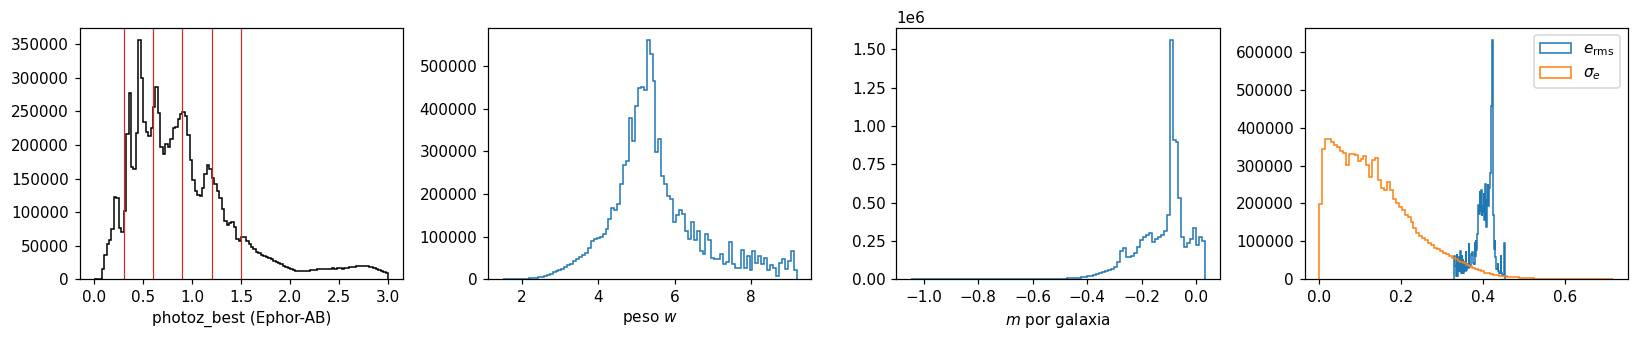

w*(erms^2+sige^2): mediana = 1.0000, std = 4.73e-08


In [3]:
allc = {k: np.concatenate([cats[f][k] for f in CAMPOS]) for k in COLS}
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
ax[0].hist(allc['zp'], bins=np.linspace(0, 3, 121), histtype='step', color='k')
for z in ZBINS: ax[0].axvline(z, color='C3', lw=.8)
ax[0].set_xlabel('photoz_best (Ephor-AB)')
ax[1].hist(allc['w'], bins=100, histtype='step'); ax[1].set_xlabel('peso $w$')
ax[2].hist(allc['m'], bins=100, histtype='step'); ax[2].set_xlabel('$m$ por galaxia')
ax[3].hist(allc['erms'], bins=100, histtype='step', label='$e_{\\rm rms}$')
ax[3].hist(allc['sige'], bins=100, histtype='step', label='$\\sigma_e$'); ax[3].legend()
plt.tight_layout(); plt.show()

# verificación: w = 1/(erms^2 + sigma_e^2)
r = allc['w'] * (allc['erms']**2 + allc['sige']**2)
print('w*(erms^2+sige^2): mediana = %.4f, std = %.2e' % (np.median(r), r.std()))

## 3. Calibración por bin tomográfico

Para cada bin $i$:

$$
\mathcal R_i = 1-\frac{\sum_j w_j e_{{\rm rms},j}^2}{\sum_j w_j},\qquad
\bar m_i=\frac{\sum_j w_j m_j}{\sum_j w_j},\qquad
n_{\rm eff}=\frac{1}{A}\frac{\left(\sum_j w_j\right)^2}{\sum_j w_j^2}.
$$

El área $A$ se aproxima contando los píxeles de 0.88′ que tienen al menos una galaxia (cota superior del área sin máscara).

In [4]:
def calibracion(cat):
    w = cat['w']
    R = 1 - np.sum(w * cat['erms']**2) / np.sum(w)
    m = np.sum(w * cat['m']) / np.sum(w)
    return R, m

def en_bin(cat, i):
    return sub(cat, (cat['zp'] > ZBINS[i]) & (cat['zp'] <= ZBINS[i+1]))

def area_deg2(cat, pix=PIX):
    p = pix / 60
    ra = cat['ra']; ra = np.where(ra - np.median(ra) > 180, ra - 360, ra)
    x = ra * np.cos(np.deg2rad(np.median(cat['dec'])))
    ix = ((x - x.min()) / p).astype(np.int64); iy = ((cat['dec'] - cat['dec'].min()) / p).astype(np.int64)
    return len(np.unique(iy * (ix.max() + 1) + ix)) * p**2

print(f'{"bin":>4s} {"N":>10s} {"R":>7s} {"m":>8s} {"n_eff [arcmin^-2]":>18s}')
A_tot = sum(area_deg2(cats[f]) for f in CAMPOS)
CAL = {}
for i in range(4):
    b = {k: np.concatenate([en_bin(cats[f], i)[k] for f in CAMPOS]) for k in ['w', 'erms', 'm']}
    R, m = calibracion(b); CAL[i] = (R, m)
    neff = np.sum(b['w'])**2 / np.sum(b['w']**2) / (A_tot * 3600)
    print(f'{i+1:>4d} {len(b["w"]):>10,d} {R:7.4f} {m:8.4f} {neff:18.2f}')
print(f'Área aproximada (5 campos): {A_tot:.1f} deg^2')

 bin          N       R        m  n_eff [arcmin^-2]


   1  2,693,375  0.8446  -0.0864               5.10


   2  2,718,958  0.8435  -0.0937               5.15


   3  2,042,075  0.8364  -0.1194               3.93


   4  1,179,636  0.8321  -0.1501               2.29
Área aproximada (5 campos): 139.8 deg^2


**Comparación:** Cheng et al. (2024) reportan $n_{\rm eff}=5.14,\,5.23,\,3.99,\,2.33$ arcmin$^{-2}$ y ~8.5 M galaxias en total, con los 6 campos y los bordes recortados. Aquí falta WIDE12H y el área es una sobreestimación, así que los números deben ser parecidos pero no idénticos.

## 4. Proyección, grilla y estimador de shear

Se usa una proyección gnomónica alrededor del centro de cada campo, con $x$ creciendo hacia el **este** (RA) e $y$ hacia el norte. En cada píxel:

$$
\hat\gamma_\alpha=\frac{1}{1+\bar m}\left[\frac{\sum_j w_j\,e_{\alpha,j}}{2\mathcal R\sum_j w_j}-\frac{\sum_j w_jc_{\alpha,j}}{\sum_j w_j}\right].
$$

**Convención de signos:** se verificó en VVDS que, con $x\to$ este y $e_2$ sin cambios, el mapa E tiene más varianza que el B y aparece un pico de ~7σ. Al invertir $e_2$, la señal pasa al modo B. Esa es la prueba estándar de paridad.

In [5]:
def proyectar(ra, dec, ra0, dec0):
    a, d, a0, d0 = map(np.deg2rad, (ra, dec, ra0, dec0))
    cosc = np.sin(d0)*np.sin(d) + np.cos(d0)*np.cos(d)*np.cos(a - a0)
    x = np.cos(d)*np.sin(a - a0) / cosc
    y = (np.cos(d0)*np.sin(d) - np.sin(d0)*np.cos(d)*np.cos(a - a0)) / cosc
    return np.rad2deg(x), np.rad2deg(y)

def geometria(cat, pix=PIX):
    ra = cat['ra']; ra = np.where(ra - np.median(ra) > 180, ra - 360, ra)
    ra0, dec0 = 0.5*(ra.min()+ra.max()), 0.5*(cat['dec'].min()+cat['dec'].max())
    x, y = proyectar(ra, cat['dec'], ra0, dec0)
    p = pix / 60
    ext = (x.min(), x.max(), y.min(), y.max())
    nx, ny = int(np.ceil((ext[1]-ext[0])/p)), int(np.ceil((ext[3]-ext[2])/p))
    return dict(ra0=ra0, dec0=dec0, ext=ext, nx=nx, ny=ny, p=p)

def grilla(cat, G, R, m, e1=None, e2=None):
    ra = np.where(cat['ra'] - G['ra0'] > 180, cat['ra'] - 360, cat['ra'])
    x, y = proyectar(ra, cat['dec'], G['ra0'], G['dec0'])
    ix = np.clip(((x - G['ext'][0]) / G['p']).astype(int), 0, G['nx']-1)
    iy = np.clip(((y - G['ext'][2]) / G['p']).astype(int), 0, G['ny']-1)
    idx = iy * G['nx'] + ix
    H = lambda v: np.bincount(idx, weights=v, minlength=G['nx']*G['ny']).reshape(G['ny'], G['nx'])
    w = cat['w']; e1 = cat['e1'] if e1 is None else e1; e2 = cat['e2'] if e2 is None else e2
    W = H(w)
    with np.errstate(invalid='ignore', divide='ignore'):
        g1 = (H(w*e1)/(2*R*W) - H(w*cat['c1'])/W) / (1+m)
        g2 = (H(w*e2)/(2*R*W) - H(w*cat['c2'])/W) / (1+m)
    g1[W == 0] = 0; g2[W == 0] = 0
    return g1, g2, W

## 5. Kaiser–Squires

En el límite de cielo plano, $\gamma = \tfrac12(\partial_1^2-\partial_2^2)\psi + i\,\partial_1\partial_2\psi$ y $\kappa=\tfrac12\nabla^2\psi$. En Fourier:

$$
\tilde\gamma(\mathbf k)=\frac{(k_1^2-k_2^2)+2ik_1k_2}{k^2}\,\tilde\kappa(\mathbf k)\equiv D(\mathbf k)\,\tilde\kappa(\mathbf k),\qquad |D|=1
\;\Longrightarrow\;
\tilde\kappa_E+i\tilde\kappa_B = D^*(\mathbf k)\,\tilde\gamma(\mathbf k).
$$

Si el campo de shear viene solo de lentes, se espera $\kappa_B=0$ salvo ruido. Por eso el modo B sirve como prueba de sistemáticos. El mapa se rellena con ceros al doble de tamaño para reducir el aliasing, y después se suaviza con una gaussiana normalizada por la máscara, $\theta_G=2'$.

In [6]:
def kaiser_squires(g1, g2, pad=2):
    ny, nx = g1.shape
    Gm = np.zeros((pad*ny, pad*nx), complex); Gm[:ny, :nx] = g1 + 1j*g2
    k1 = np.fft.fftfreq(pad*nx)[None, :]; k2 = np.fft.fftfreq(pad*ny)[:, None]
    ksq = k1**2 + k2**2; ksq[0, 0] = 1
    D = (k1**2 - k2**2 + 2j*k1*k2) / ksq
    k = np.fft.ifft2(np.conj(D) * np.fft.fft2(Gm))[:ny, :nx]
    return k.real, k.imag

def suavizar(mapa, W, theta=THETA_G, pix=PIX, umbral=0.5):
    s = theta / pix
    msk = (W > 0).astype(float)
    num = gaussian_filter(mapa * msk, s, mode='constant'); den = gaussian_filter(msk, s, mode='constant')
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(den > umbral, num / den, np.nan)

def rotar(cat):
    phi = rng.uniform(0, np.pi, len(cat['e1']))
    c, s = np.cos(2*phi), np.sin(2*phi)
    return cat['e1']*c - cat['e2']*s, cat['e1']*s + cat['e2']*c

## 6. Mapas $\kappa_E$, $\kappa_B$ y S/N (todas las galaxias $0.3<z<1.5$)

El ruido se estima **rotando aleatoriamente** cada galaxia. Eso destruye la señal coherente de lentes y conserva la distribución espacial y el *shape noise*.

Hay un detalle estadístico. Si $\sigma$ se estima píxel a píxel con pocas rotaciones, $\kappa/\hat\sigma$ sigue una distribución tipo *t de Student*, con colas infladas, y eso fabrica picos falsos. Por eso:
1. se promedia la varianza de $N_{\rm rot}=20$ rotaciones y se **suaviza** el mapa de varianza, porque $\sigma$ varía lentamente, al ritmo de la densidad de galaxias;
2. los mapas de ruido usados como referencia en el conteo de picos son rotaciones **independientes** de las que definen $\sigma$.

In [7]:
NROT, NTEST = 20, 5
def mapa_ruido(c, G, R, m, W):
    r1, r2 = rotar(c)
    n1, n2, _ = grilla(c, G, R, m, r1, r2)
    return suavizar(kaiser_squires(n1, n2)[0], W)

MAPAS = {}
for f in CAMPOS:
    c = sub(cats[f], (cats[f]['zp'] > 0.3) & (cats[f]['zp'] <= 1.5))
    R, m = calibracion(c); G = geometria(c)
    g1, g2, W = grilla(c, G, R, m)
    kE, kB = kaiser_squires(g1, g2)
    E, B = suavizar(kE, W), suavizar(kB, W)
    var = np.nanmean(np.array([mapa_ruido(c, G, R, m, W)**2 for _ in range(NROT)]), axis=0)
    ok = np.isfinite(var)
    var_s = gaussian_filter(np.where(ok, var, 0), 5) / gaussian_filter(ok.astype(float), 5)   # suavizado ~4.4'
    sig = np.where(ok, np.sqrt(var_s), np.nan)
    test = [mapa_ruido(c, G, R, m, W) / sig for _ in range(NTEST)]
    MAPAS[f] = dict(E=E, B=B, SN_E=E/sig, SN_B=B/sig, G=G, SN_ruido=test)
    print(f'{f:9s} std(E)={np.nanstd(E):.4f}  std(B)={np.nanstd(B):.4f}  std(ruido)={np.nanmean(sig):.4f}  max S/N_E={np.nanmax(E/sig):.1f}')

/sessions/rcw-016xs7ieinevt5x8lrlcct4p/tmp/ipykernel_11/1131722884.py:14: RuntimeWarning: Mean of empty slice
  var = np.nanmean(np.array([mapa_ruido(c, G, R, m, W)**2 for _ in range(NROT)]), axis=0)
/sessions/rcw-016xs7ieinevt5x8lrlcct4p/tmp/ipykernel_11/1131722884.py:16: RuntimeWarning: invalid value encountered in divide
  var_s = gaussian_filter(np.where(ok, var, 0), 5) / gaussian_filter(ok.astype(float), 5)   # suavizado ~4.4'


vvds      std(E)=0.0131  std(B)=0.0114  std(ruido)=0.0111  max S/N_E=6.5


xmm       std(E)=0.0128  std(B)=0.0114  std(ruido)=0.0112  max S/N_E=7.4


hectomap  std(E)=0.0124  std(B)=0.0112  std(ruido)=0.0108  max S/N_E=6.8


gama15h   std(E)=0.0128  std(B)=0.0111  std(ruido)=0.0107  max S/N_E=7.7


gama09h   std(E)=0.0136  std(B)=0.0123  std(ruido)=0.0120  max S/N_E=6.9


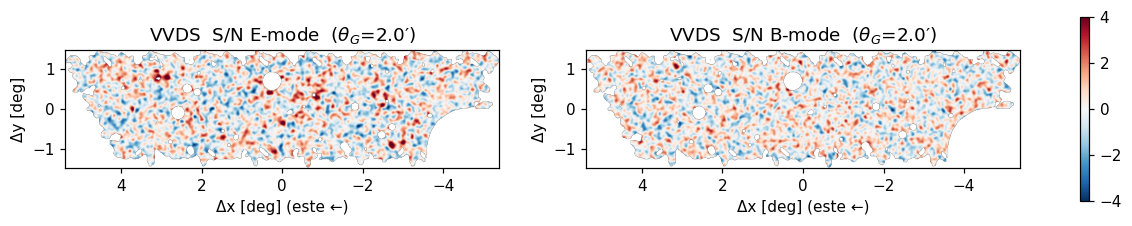

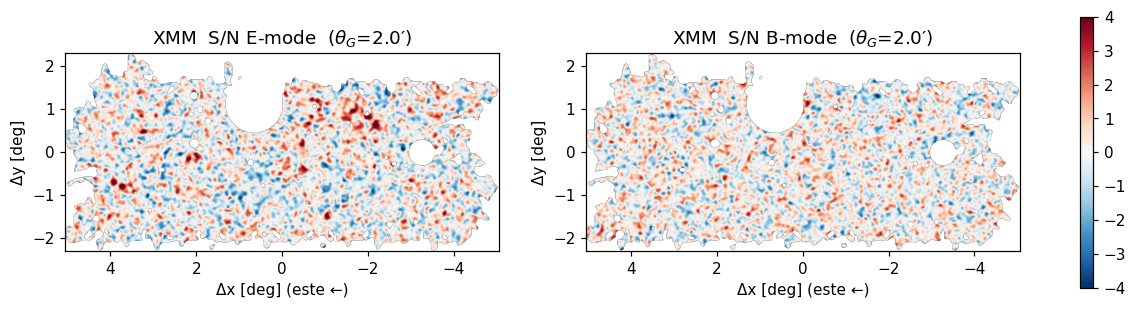

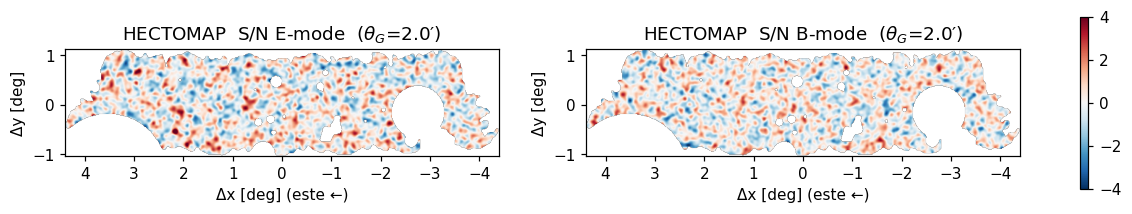

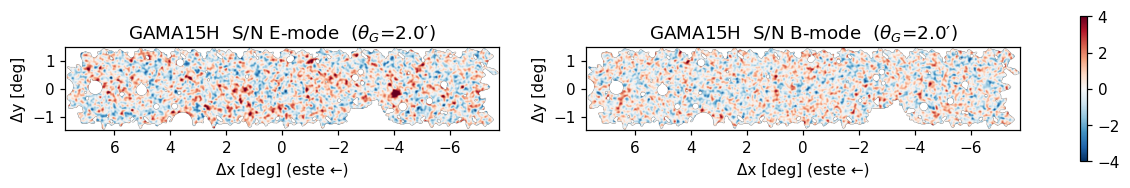

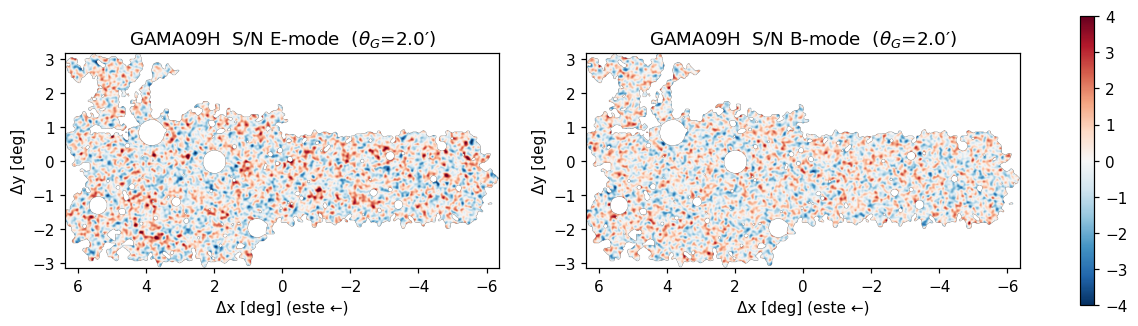

In [8]:
for f in CAMPOS:
    M = MAPAS[f]; G = M['G']
    ext = [G['ext'][1], G['ext'][0], G['ext'][2], G['ext'][3]]   # este a la izquierda, como en el cielo
    fig, ax = plt.subplots(1, 2, figsize=(14, 14*G['ny']/G['nx']/2 + 0.8))
    for a, k, t in zip(ax, ['SN_E', 'SN_B'], ['E-mode', 'B-mode']):
        im = a.imshow(M[k][:, ::-1], extent=ext, vmin=-4, vmax=4, cmap='RdBu_r', aspect='equal')
        a.set_title(f'{f.upper()}  S/N {t}  ($\\theta_G$={THETA_G}′)'); a.set_xlabel('Δx [deg] (este ←)'); a.set_ylabel('Δy [deg]')
    plt.colorbar(im, ax=ax, shrink=.8); plt.show()

## 7. Primer estadístico no gaussiano: conteo de picos

Un *pico* es un píxel mayor que sus 8 vecinos. Su histograma en S/N depende fuertemente de $S_8$, porque los picos altos trazan halos masivos. Como prueba de sistemáticos:
- los picos del modo B deben coincidir con los del ruido;
- los picos del modo E deben mostrar un **exceso en la cola de S/N alto**.

Este estadístico es el que estudian Grandón et al. (2024) junto con los mínimos, la PDF y el scattering transform.

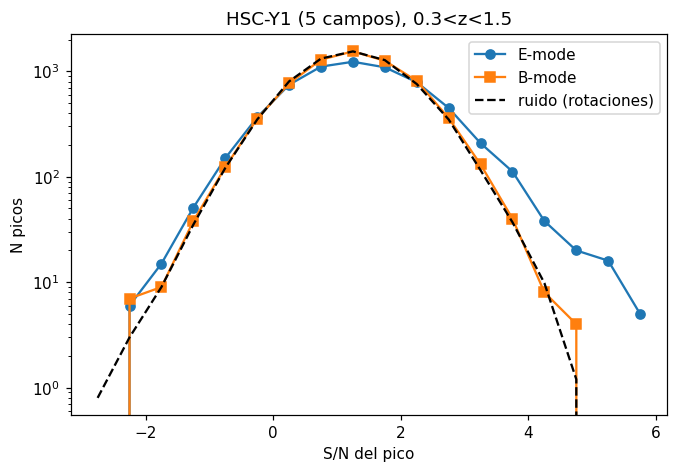

E      picos con S/N>4: 79   S/N>5: 21
B      picos con S/N>4: 12   S/N>5: 0
ruido  picos con S/N>4: 11   S/N>5: 0


In [9]:
def picos(mapa):
    m = np.nan_to_num(mapa, nan=-np.inf)
    es = (m == maximum_filter(m, size=3, mode='constant', cval=-np.inf)) & np.isfinite(mapa)
    return mapa[es]

bins = np.linspace(-3, 6, 19); cen = 0.5*(bins[1:]+bins[:-1])
hE = sum(np.histogram(picos(MAPAS[f]['SN_E']), bins)[0] for f in CAMPOS)
hB = sum(np.histogram(picos(MAPAS[f]['SN_B']), bins)[0] for f in CAMPOS)
hN = np.mean([sum(np.histogram(picos(MAPAS[f]['SN_ruido'][r]), bins)[0] for f in CAMPOS) for r in range(NTEST)], axis=0)
plt.figure(figsize=(7, 4.5))
plt.semilogy(cen, hE, 'o-', label='E-mode'); plt.semilogy(cen, hB, 's-', label='B-mode')
plt.semilogy(cen, hN, 'k--', label='ruido (rotaciones)')
plt.xlabel('S/N del pico'); plt.ylabel('N picos'); plt.legend(); plt.title('HSC-Y1 (5 campos), 0.3<z<1.5')
plt.show()
for t, h in [('E', hE), ('B', hB), ('ruido', hN)]:
    print(f'{t:6s} picos con S/N>4: {h[cen > 4].sum():.0f}   S/N>5: {h[cen > 5].sum():.0f}')

## Próximos pasos

- **Validar con publicaciones:** comparar con los mapas de Oguri et al. (2018), disponibles en el archivo de HSC (`pdr1_hscwl/Oguri/`), que usan el mismo suavizado de 2′.
- **Tomografía:** repetir la sección 6 con `en_bin(cat, i)` para cada bin. Así se obtienen los 4 mapas que usan Cheng, Marques y Grandón.
- **Espectro de potencia** $C_\ell$ con NaMaster, para comparar con los band powers de Hikage et al. (2019).
- **Más estadísticos no gaussianos:** mínimos, PDF, funcionales de Minkowski, scattering transform.
- **Restricciones cosmológicas:** requieren los 2268 mocks (covarianza, públicos, 1.7 TB) y las simulaciones *cosmo-varied* (emulador, a pedido de los autores).
- **Falta WIDE12H:** encolar de nuevo con la función correcta (revisar *function list* en el sitio).